# 06 · Más ejemplos: entrenar con otros nodos de la red

**Punto de partida.** Cada modelo aprende de una sola serie, la de Monclova, y con el MTR disponible hasta *d−8* tiene unos 300 días de ejemplos. A LEAR le alcanza porque tiene pocos parámetros efectivos. Al gradient boosting (GB) y a las redes no: el GB solo con Monclova quedó peor que el MDA (notebook 05) y las redes, en el mejor caso, lo igualan.

**La idea.** El error del MDA es sobre todo energía, y la energía es la misma en todo el país (notebooks 02 y 03). Otros nodos de la red son entonces ejemplos extra de cómo se equivoca el MDA, aunque lo que se pronostica siga siendo solo Monclova. Se prueba primero con el GB, que es el que más sufre por falta de datos, y luego con todos los modelos. Todo se mide en desarrollo (MAE en MXN/MWh y % contra el MDA o contra la misma versión con solo Monclova).

In [1]:
import os
for k in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'): os.environ[k] = '1'   # evita sobresuscripción en procesos paralelos
import sys, warnings, pickle
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dataclasses import replace
from pml import plotstyle as ps
ps.aplicar()
FIG = ROOT / 'reports/figures'; REP = ROOT / 'reports'

from pml import features2 as f2, exp, dl, red, multinodo as mn, referencias as rf
from pml.metrics import mae
R = rf.cargar()                          # los pronósticos ya establecidos (notebooks 04 y 05), desde caché
cb, Y, X = R.cb, R.Y, R.X
DEV, DIAS = exp.idx_dev(), exp.dias_eval(R.c0)
m = R.mae
Xtb = f2._t(cb)[1]
inv_s = lambda P: f2.inv(P + Xtb.loc[P.index], cb)          # del spread pronosticado al precio
tabla = lambda filas, archivo: (lambda T: (display(T), T.to_csv(REP / archivo)))(exp.comparar(Y, filas, X, registrar_como='nb09'))
print(f"MDA {m(X):.1f} | LEAR base {m(R.P['LEAR base']):.1f} | GB base {m(R.P['GB base']):.1f} | TiDE V3 {m(R.P['TiDE V3']):.1f}  (MAE de desarrollo, MXN/MWh)")

MDA 221.6 | LEAR base 219.2 | GB base 229.4 | TiDE V3 219.7  (MAE de desarrollo, MXN/MWh)


## 1. ¿Qué tan parecidos son los otros nodos a Monclova?

nodos de la red: 64 | parecido mediano 0.94 | entre 0.56 y 1.00


,median,min,max,size
corredor,,,,
carbon,1.00,1.00,1.00,3
monterrey,1.00,1.00,1.00,8
saltillo,1.00,1.00,1.00,2
tamaulipas,0.95,0.93,1.00,11
norte,0.94,0.85,0.94,3
occidente,0.92,0.87,0.98,15
centro,0.81,0.73,0.84,5
oriente,0.60,0.58,0.78,12
peninsular,0.58,0.58,0.58,2


origen
31 originales    0.91
400 kV nuevos    0.94
Name: parecido con Monclova, dtype: float64

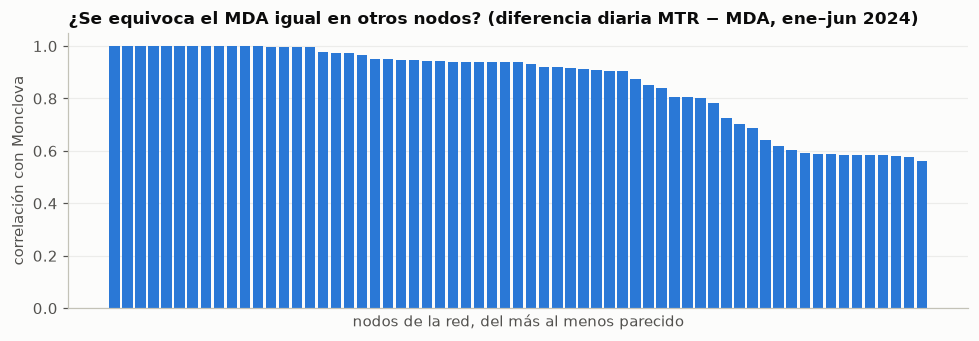

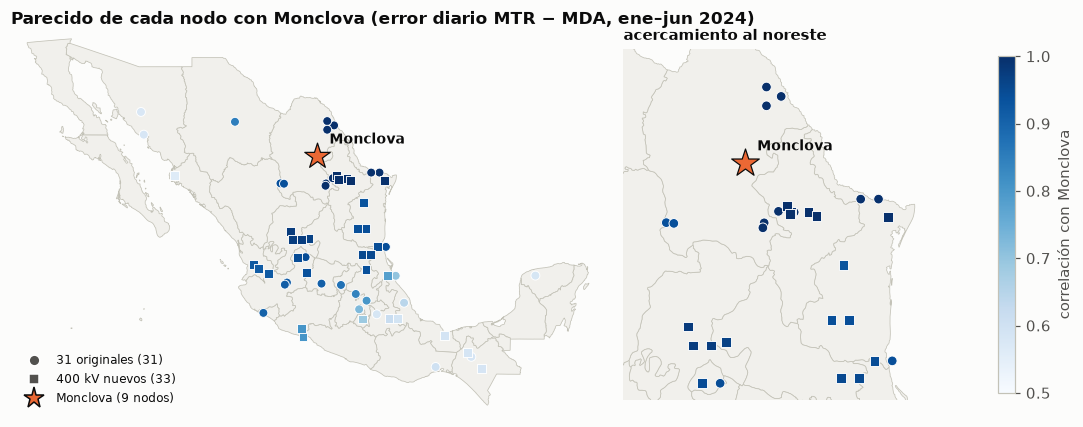

In [2]:
# Parecido de cada nodo con Monclova: correlación de rangos del error diario MTR − MDA, sólo con días de ene–jun 2024
# (antes del desarrollo, porque esta misma medida se usa después para elegir nodos)
rho, _ = mn.parecidos(R.c0, 10, troncal=True)
cor = red.corredores(troncal=True)
rr = pd.DataFrame({'parecido con Monclova': rho, 'corredor': [cor[n] for n in rho.index], 'origen': ['31 originales' if n in red.NODOS_RED else '400 kV nuevos' for n in rho.index]})
print(f"nodos de la red: {len(rr)} | parecido mediano {rr['parecido con Monclova'].median():.2f} | entre {rr['parecido con Monclova'].min():.2f} y {rr['parecido con Monclova'].max():.2f}")
display(rr.groupby('corredor')['parecido con Monclova'].agg(['median', 'min', 'max', 'size']).sort_values('median', ascending=False).round(2))
display(rr.groupby('origen')['parecido con Monclova'].median().round(2))
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(range(len(rr)), rr['parecido con Monclova'].values, color=ps.AZUL, width=0.8)
ax.set_xticks([]); ax.set_xlabel('nodos de la red, del más al menos parecido'); ax.set_ylabel('correlación con Monclova')
ax.set_title('¿Se equivoca el MDA igual en otros nodos? (diferencia diaria MTR − MDA, ene–jun 2024)')
fig.tight_layout(); fig.savefig(FIG / '06_parecido_nodos.png'); plt.show()
# el mismo parecido, en el mapa: cada nodo en su municipio (ubicación aproximada), Monclova como estrella
from pml import mapas
ub = red.ubicaciones()
fig = plt.figure(figsize=(12, 4.8))
a1 = fig.add_axes([0.0, 0.05, 0.56, 0.85]); a2 = fig.add_axes([0.58, 0.05, 0.3, 0.85])
mapas.fondo(a1); sc = mapas.nodos(a1, ub, rho, vmin=0.5, vmax=1, etiqueta=True, leyenda=True)
a1.set_title('Parecido de cada nodo con Monclova (error diario MTR − MDA, ene–jun 2024)')
mapas.fondo(a2, **mapas.NORESTE); mapas.nodos(a2, ub, rho, vmin=0.5, vmax=1, etiqueta=True, tam=40); a2.set_title('acercamiento al noreste', fontsize=10)
fig.colorbar(sc, ax=[a1, a2], shrink=0.75, label='correlación con Monclova')
fig.savefig(FIG / '06_mapa_parecido.png', bbox_inches='tight'); plt.show()

Hay 64 nodos con datos en la troncal de 400 kV. El error del MDA en la mayoría se parece mucho al de Monclova (correlación mediana de 0.94). Los del carbón, Saltillo y Monterrey se mueven igual (1.00); Tamaulipas, el norte y el occidente quedan entre 0.92 y 0.95; el centro en 0.81; el oriente, Sonora y Mérida cerca de 0.6.

Confirma que el error es casi todo energía y que el parecido sigue la geografía: la congestión local es lo que cambia entre regiones.

**Por qué se empezó con 31 nodos.** Se eligieron a mano, antes de medir nada, por el papel que juegan en la red: el corredor del carbón y Saltillo junto a Monclova, los grandes centros de carga (Monterrey, Ciudad de México, Guadalajara, el Bajío), el enlace con Texas y los puntos de gas y GNL (Altamira, Manzanillo), y una muestra del resto del país con tecnologías distintas (nuclear, hidro, eólica, solar, Mérida) para tener variedad. No hubo un algoritmo de selección. En la sección 3 se añaden los 33 nodos restantes de 400 kV para comprobar si más era mejor.

## 2. La primera prueba: gradient boosting con 31 nodos

In [3]:
# Primera prueba: el GB del notebook 05 entrenado (1) sólo con Monclova, (2) con Monclova y 31 nodos, (3) igual pero
# con Monclova pesando 10 veces más. Siempre se pronostica y se evalúa sólo Monclova. Resultados en caché
fgb = ROOT / 'data/processed/exp_cache/gb_multinodo.pkl'
if fgb.exists(): GBM = pickle.loads(fgb.read_bytes())
else:
    L1, y1 = mn.preparar(cb, con_red=False); La, ya = mn.preparar(cb, con_red=True)
    GBM = {'solo Monclova': mn.correr(L1, y1, DIAS), 'Monclova + 31 nodos': mn.correr(La, ya, DIAS),
           'Monclova + 31 nodos, Monclova pesa 10': mn.correr(La, ya, DIAS, peso_mon=10.0)}
    fgb.write_bytes(pickle.dumps(GBM))
# del error pronosticado (escala del proyecto) al precio en MXN/MWh
GB0, GB31 = inv_s(GBM['solo Monclova']), inv_s(GBM['Monclova + 31 nodos'])
LEAR = R.P['LEAR base']
tabla([('referencias', 'MDA', X, None), ('referencias', 'LEAR base', LEAR, None), ('referencias', 'GB base (notebook 05)', R.P['GB base'], None),
       ('GB', 'GB solo Monclova', GB0, None), ('GB', 'GB + 31 nodos', GB31, 'GB solo Monclova'),
       ('GB', 'GB + 31 nodos, Monclova pesa 10', inv_s(GBM['Monclova + 31 nodos, Monclova pesa 10']), 'GB solo Monclova'),
       ('GB', 'GB + 31 nodos contra el GB del notebook 05', GB31, 'GB base (notebook 05)'),
       ('mezcla', 'LEAR + GB base (50/50)', (LEAR + R.P['GB base']) / 2, None),
       ('mezcla', 'LEAR + GB 31 nodos (50/50)', (LEAR + GB31) / 2, 'LEAR + GB base (50/50)')], '06_gb31_dev.csv')

MAE  vs MDA (%)  \
grupo       modelo                                                          
referencias MDA                                         221.6         0.0   
            LEAR base                                   219.2        -1.1   
            GB base (notebook 05)                       229.4         3.5   
GB          GB solo Monclova                            235.3         6.2   
            GB + 31 nodos                               219.8        -0.8   
            GB + 31 nodos, Monclova pesa 10             222.3         0.3   
            GB + 31 nodos contra el GB del notebook 05  219.8        -0.8   
mezcla      LEAR + GB base (50/50)                      221.1        -0.2   
            LEAR + GB 31 nodos (50/50)                  215.8        -2.6   

                                                                    referencia  \
grupo       modelo                                                               
referencias MDA                                                                  
            LEAR base                                                            
            GB base (notebook 05)                                                
GB          GB solo Monclova                                                     
            GB + 31 nodos                                     GB solo Monclova   
            GB + 31 nodos, Monclova pesa 10                   GB solo Monclova   
            GB + 31 nodos contra el GB del notebook 05   GB base (notebook 05)   
mezcla      LEAR + GB base (50/50)                                               
            LEAR + GB 31 nodos (50/50)                  LEAR + GB base (50/50)   

                                                       vs referencia (%)  \
grupo       modelo                                                         
referencias MDA                                                            
            LEAR base                                                      
            GB base (notebook 05)                                          
GB          GB solo Monclova                                               
            GB + 31 nodos                                           -6.6   
            GB + 31 nodos, Monclova pesa 10                         -5.5   
            GB + 31 nodos contra el GB del notebook 05              -4.2   
mezcla      LEAR + GB base (50/50)                                         
            LEAR + GB 31 nodos (50/50)                              -2.4   

                                                       meses mejor      p  
grupo       modelo                                                         
referencias MDA                                                            
            LEAR base                                                      
            GB base (notebook 05)                                          
GB          GB solo Monclova                                               
            GB + 31 nodos                                   6 de 6    0.0  
            GB + 31 nodos, Monclova pesa 10                 6 de 6    0.0  
            GB + 31 nodos contra el GB del notebook 05      5 de 6  0.012  
mezcla      LEAR + GB base (50/50)                                         
            LEAR + GB 31 nodos (50/50)                      5 de 6  0.007

(None, None)

El GB solo con Monclova queda en 235.3, 6.2% peor que el MDA (esta versión incluye las estadísticas móviles, por eso difiere del 229.4 del notebook 05). Con los 31 nodos baja a 219.8: 6.6% menos error que su versión solo con Monclova y 4.2% menos que el GB del notebook 05. Darle a Monclova diez veces más peso empeora (222.3). En la mezcla, LEAR + GB pasa de 221.1 a 215.8.

Al GB le faltaban ejemplos, no complejidad. Y le conviene tratar a todos los nodos como ejemplos igual de valiosos.

Es la mejora más grande de una sola idea hasta ahora. Falta ver si más nodos ayudan más, y si ayudan a los demás modelos.

## 3. Toda la troncal de 400 kV, en todos los modelos

In [4]:
nod = red.matrices_nodo('MTR', troncal=True)
print(f"series de entrenamiento: Monclova + {sum(n in red.NODOS_RED for n in nod)} nodos originales + {sum(n in red.NODOS_400 for n in nod)} de 400 kV con datos = {1 + len(nod)}")
# GB con la troncal: mediana y cuantiles 10 y 90
fgb8 = ROOT / 'data/processed/exp_cache/gb_troncal.pkl'
if fgb8.exists(): GB8 = pickle.loads(fgb8.read_bytes())
else:
    Lt, yt = mn.preparar(cb, con_red=True, troncal=True)
    GB8 = {'mediana': mn.correr(Lt, yt, DIAS), **{q: mn.correr(Lt, yt, DIAS, quantile=q) for q in (0.1, 0.9)}}
    fgb8.write_bytes(pickle.dumps(GB8)); del Lt, yt
GB65 = inv_s(GB8['mediana'])
# LEAR con 31 y 64 nodos: mismo protocolo que LEAR base (recalibración diaria, tres ventanas, alpha elegido en desarrollo)
LEAR31 = exp.pronostico(cb, mn.lear(cb, DIAS, troncal=False))[0]
LEAR65 = exp.pronostico(cb, mn.lear(cb, DIAS, troncal=True))[0]
# redes ancladas al MDA: la configuración de siempre y la misma con L1 / 10
NOMBRE = {'mlp': 'DNN', 'nbeats': 'NBEATSx', 'tide': 'TiDE'}
SOLO = {'DNN': R.P['DNN V3'], 'NBEATSx': R.P['NBEATSx V3'], 'TiDE': R.P['TiDE V3']}
RED65, L1_ELEGIDO = {}, {}
for a, k in NOMBRE.items():
    h = replace(R.hp[a], batch=256)
    opc = {f'L1 = {h.l1:g}': h, f'L1 = {h.l1 / 10:g}': replace(h, l1=h.l1 / 10)}
    P = {e: dl.a_precios(cb, dl.correr_dl_red(cb, 'spread', hh, DIAS, troncal=True, nombre=f'{a}_troncal'), 'spread') for e, hh in opc.items()}
    L1_ELEGIDO[k] = min(P, key=lambda e: m(P[e])); RED65[k] = P[L1_ELEGIDO[k]]
    print(f"{k} V3 con 64 nodos: " + ' | '.join(f'{e}: {m(Pe):.1f}' for e, Pe in P.items()) + f"  → nos quedamos con {L1_ELEGIDO[k]}")
NB1_65 = dl.a_precios(cb, dl.correr_dl_red(cb, 'sin_mda', replace(R.hp['nbeats'], batch=256), DIAS, troncal=True, nombre='nbeats_troncal'), 'sin_mda')


series de entrenamiento: Monclova + 31 nodos originales + 33 de 400 kV con datos = 65
DNN V3 con 64 nodos: L1 = 3: 245.0 | L1 = 0.3: 263.1  → nos quedamos con L1 = 3
NBEATSx V3 con 64 nodos: L1 = 3: 229.1 | L1 = 0.3: 265.9  → nos quedamos con L1 = 3
TiDE V3 con 64 nodos: L1 = 3: 253.0 | L1 = 0.3: 246.2  → nos quedamos con L1 = 0.3


In [5]:
# Tabla de la sección 3: cada modelo con la red contra su versión entrenada sólo con Monclova
filas3 = [('referencias', 'MDA', X, None), ('referencias', 'LEAR base', LEAR, None),
          ('GB', 'GB solo Monclova', GB0, None), ('GB', 'GB + 31 nodos', GB31, 'GB solo Monclova'), ('GB', 'GB + 64 nodos', GB65, 'GB solo Monclova'),
          ('LEAR', 'LEAR + 31 nodos', LEAR31, 'LEAR base'), ('LEAR', 'LEAR + 64 nodos', LEAR65, 'LEAR base'),
          *[x for k in SOLO for x in ((k, f'{k} solo Monclova', SOLO[k], None), (k, f'{k} + 64 nodos', RED65[k], f'{k} solo Monclova'))],
          ('NBEATSx sin MDA', 'NBEATSx sin MDA solo Monclova', R.P['NBEATSx V1 sin MDA'], None),
          ('NBEATSx sin MDA', 'NBEATSx sin MDA + 64 nodos', NB1_65, 'NBEATSx sin MDA solo Monclova'),]
tabla(filas3, '06_troncal_dev.csv')
# intervalos 10–90: el GB de cuantiles del notebook 05 contra el mismo entrenado con 64 nodos
from pml.gb2 import pinball
yv = Y.loc[DEV].values
QB = pickle.loads((ROOT / 'data/processed/exp_cache/q_Q_base_G0pG2.pkl').read_bytes())
QT = {'GB de cuantiles, solo Monclova (notebook 05)': {q: f2.inv(QB[q].loc[DEV] + Xtb.loc[DEV], cb).values for q in (0.1, 0.9)},
      'GB de cuantiles + 64 nodos': {q: inv_s(GB8[q]).loc[DEV].values for q in (0.1, 0.9)}}
display(pd.DataFrame({k: {'horas dentro del intervalo 10–90 (%)': 100 * ((yv >= Q[0.1]) & (yv <= Q[0.9])).mean(), 'anchura mediana (MXN/MWh)': np.median(Q[0.9] - Q[0.1]),
                          'pérdida pinball media': np.mean([pinball(yv, Q[q], q) for q in (0.1, 0.9)])} for k, Q in QT.items()}).T.round(1))

MAE  vs MDA (%)  \
grupo           modelo                                             
referencias     MDA                            221.6         0.0   
                LEAR base                      219.2        -1.1   
GB              GB solo Monclova               235.3         6.2   
                GB + 31 nodos                  219.8        -0.8   
                GB + 64 nodos                  219.5        -0.9   
LEAR            LEAR + 31 nodos                218.3        -1.5   
                LEAR + 64 nodos                218.8        -1.3   
DNN             DNN solo Monclova              221.3        -0.1   
                DNN + 64 nodos                 245.0        10.6   
NBEATSx         NBEATSx solo Monclova          222.9         0.6   
                NBEATSx + 64 nodos             229.1         3.4   
TiDE            TiDE solo Monclova             219.7        -0.8   
                TiDE + 64 nodos                246.2        11.1   
NBEATSx sin MDA NBEATSx sin MDA solo Monclova  257.6        16.2   
                NBEATSx sin MDA + 64 nodos     269.9        21.8   

                                                                  referencia  \
grupo           modelo                                                         
referencias     MDA                                                            
                LEAR base                                                      
GB              GB solo Monclova                                               
                GB + 31 nodos                               GB solo Monclova   
                GB + 64 nodos                               GB solo Monclova   
LEAR            LEAR + 31 nodos                                    LEAR base   
                LEAR + 64 nodos                                    LEAR base   
DNN             DNN solo Monclova                                              
                DNN + 64 nodos                             DNN solo Monclova   
NBEATSx         NBEATSx solo Monclova                                          
                NBEATSx + 64 nodos                     NBEATSx solo Monclova   
TiDE            TiDE solo Monclova                                             
                TiDE + 64 nodos                           TiDE solo Monclova   
NBEATSx sin MDA NBEATSx sin MDA solo Monclova                                  
                NBEATSx sin MDA + 64 nodos     NBEATSx sin MDA solo Monclova   

                                              vs referencia (%) meses mejor  \
grupo           modelo                                                        
referencias     MDA                                                           
                LEAR base                                                     
GB              GB solo Monclova                                              
                GB + 31 nodos                              -6.6      6 de 6   
                GB + 64 nodos                              -6.7      6 de 6   
LEAR            LEAR + 31 nodos                            -0.4      3 de 6   
                LEAR + 64 nodos                            -0.2      3 de 6   
DNN             DNN solo Monclova                                             
                DNN + 64 nodos                             10.7      0 de 6   
NBEATSx         NBEATSx solo Monclova                                         
                NBEATSx + 64 nodos                          2.8      2 de 6   
TiDE            TiDE solo Monclova                                            
                TiDE + 64 nodos                            12.0      1 de 6   
NBEATSx sin MDA NBEATSx sin MDA solo Monclova                                 
                NBEATSx sin MDA + 64 nodos                  4.8      2 de 6   

                                                   p  
grupo           modelo                                
referencias     MDA                                   
                LEAR b

,horas dentro del intervalo 10–90 (%),anchura mediana (MXN/MWh),pérdida pinball media
"GB de cuantiles, solo Monclova (notebook 05)",80.9,411.9,61.1
GB de cuantiles + 64 nodos,77.4,334.5,57.8


Con los 64 nodos el GB queda igual que con 31 (219.5 contra 219.8). LEAR casi no cambia (218.3 con 31 y 218.8 con 64, contra 219.2). Las redes empeoran: la DNN 10.6%, TiDE 11.1%, NBEATSx 3.4% y la red sin MDA 21.8%. Bajar la penalización no lo arregla (DNN y NBEATSx quedaron peor, TiDE solo un poco mejor con 246.2). Los intervalos del GB de cuantiles con 64 nodos son más angostos (334 contra 412 MXN/MWh) y en desarrollo cubren 77.4% de las horas contra 80.9%.

Más datos ayudan a quien los necesita (el GB) y no a LEAR, que ya tenía suficientes. A las redes les hacen daño, y no se comprobó a fondo; una explicación posible es que los otros nodos arrastran la red hacia patrones que no son los de Monclova.

El GB es el que más gana con la red. Aun así, para que todos los modelos pasen por el mismo camino, desde aquí todos se entrenan con los 64 nodos (ver "Decisiones").

In [6]:
# El GB del pipeline común (notebooks 07 y 08): con 64 nodos pero solo con las variables base de todos los modelos (rezagos del MTR,
# MDA y su error), sin las estadísticas móviles. Calculado en el servidor (src/pml/servidor.py, `gb:nodos`)
GB64_BASE = inv_s(pickle.loads((ROOT / 'data/processed/exp_cache/esc_gb_nodos.pkl').read_bytes()))
tabla([('referencias', 'MDA', X, None), ('GB', 'GB base solo Monclova (notebook 05)', R.P['GB base'], None),
       ('GB', 'GB base + 64 nodos', GB64_BASE, 'GB base solo Monclova (notebook 05)'),
       ('GB', 'GB con estadísticas móviles + 64 nodos', GB65, 'GB base + 64 nodos')], '06_gb_base64_dev.csv')

MAE  vs MDA (%)  \
grupo       modelo                                                      
referencias MDA                                     221.6         0.0   
GB          GB base solo Monclova (notebook 05)     229.4         3.5   
            GB base + 64 nodos                      222.3         0.3   
            GB con estadísticas móviles + 64 nodos  219.5        -0.9   

                                                                             referencia  \
grupo       modelo                                                                        
referencias MDA                                                                           
GB          GB base solo Monclova (notebook 05)                                           
            GB base + 64 nodos                      GB base solo Monclova (notebook 05)   
            GB con estadísticas móviles + 64 nodos                   GB base + 64 nodos   

                                                   vs referencia (%)  \
grupo       modelo                                                     
referencias MDA                                                        
GB          GB base solo Monclova (notebook 05)                        
            GB base + 64 nodos                                  -3.1   
            GB con estadísticas móviles + 64 nodos              -1.3   

                                                   meses mejor      p  
grupo       modelo                                                     
referencias MDA                                                        
GB          GB base solo Monclova (notebook 05)                        
            GB base + 64 nodos                          6 de 6    0.0  
            GB con estadísticas móviles + 64 nodos      2 de 6  0.074

(None, None)

Con las mismas variables que todos los modelos (rezagos del MTR, MDA y su error), entrenar el GB con los 64 nodos lo baja de 229.4 a 222.3 MXN/MWh: 3.1% menos error, mejor en los 6 meses (*p* < 0.01). Con eso queda prácticamente al nivel del MDA (+0.3%). Sumarle además las estadísticas móviles lo lleva a 219.5, otro 1.3%, pero solo mejor en 2 de 6 meses (*p* = 0.07).

La mayor parte de lo que gana el GB viene de los ejemplos extra, no de las variables. Las estadísticas móviles agregan algo encima, menos consistente.

Esta versión, con 64 nodos y solo las variables base, es el punto de partida común de todos los modelos en los notebooks siguientes.

## 4. ¿Por qué 64 nodos no mejoran sobre 31?

In [7]:
# ¿Qué pasa si solo se usan los 15 nodos más parecidos a Monclova? (se entrena una vez y se guarda en caché)
fgb4 = ROOT / 'data/processed/exp_cache/gb_decisiones.pkl'
D4 = pickle.loads(fgb4.read_bytes()) if fgb4.exists() else {}
_, PAR15 = mn.parecidos(R.c0, 15, troncal=True)
print('los 15 nodos más parecidos:', ', '.join(f'{n} ({cor[n]})' for n in PAR15))
# entrena (o lee de caché) una variante del GB con la red y la devuelve en MXN/MWh
def gb(nombre, **kw):
    if nombre not in D4:
        sin, afinar = kw.pop('sin_ident', False), kw.pop('afinar', 0)
        L, y = mn.preparar(cb, con_red=True, troncal=True, **kw)
        D4[nombre] = mn.correr(L, y, DIAS, sin_ident=sin, afinar=afinar); fgb4.write_bytes(pickle.dumps(D4))
    return inv_s(D4[nombre])
DEC = {'solo los 15 nodos más parecidos': gb('15 parecidos', nodos=PAR15)}


los 15 nodos más parecidos: 06VDG-230 (monterrey), 06ESC-400 (monterrey), 06CBD-400 (carbon), 06FAI-400 (monterrey), 06REC-400 (carbon), 06HYM-400 (monterrey), 06NAV-138 (carbon), 06TRQ-400 (monterrey), 06RAP-400 (saltillo), 06SAL-115 (saltillo), 06HUO-400 (monterrey), 06CDU-400 (monterrey), 06PGE-400 (monterrey), 06AER-400 (tamaulipas), 06CUF-230 (tamaulipas)


,series de entrenamiento,series efectivamente distintas,error del GB en desarrollo,GB vs solo Monclova (%)
solo Monclova,1,1.00,235.26,0.00
Monclova + 15 más parecidos,16,1.00,233.04,-0.94
Monclova + 31 originales,32,1.53,219.81,-6.57
Monclova + 64,64,1.47,219.54,-6.68


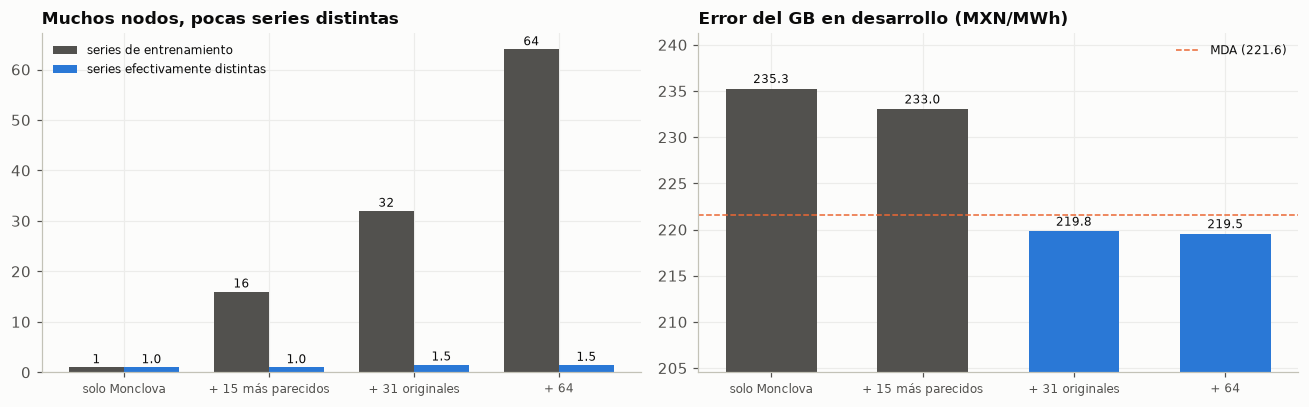

nodos por grupo: {'grupo 1': 44, 'grupo 2': 16, 'grupo 3': 3, 'grupo 4': 1} | Monclova está en el grupo 1
series efectivas de Monclova junto con cada grupo: {'grupo 1': np.float64(1.09), 'grupo 2': np.float64(1.27), 'grupo 3': np.float64(1.44), 'grupo 4': np.float64(1.27)} | con todos: 1.47


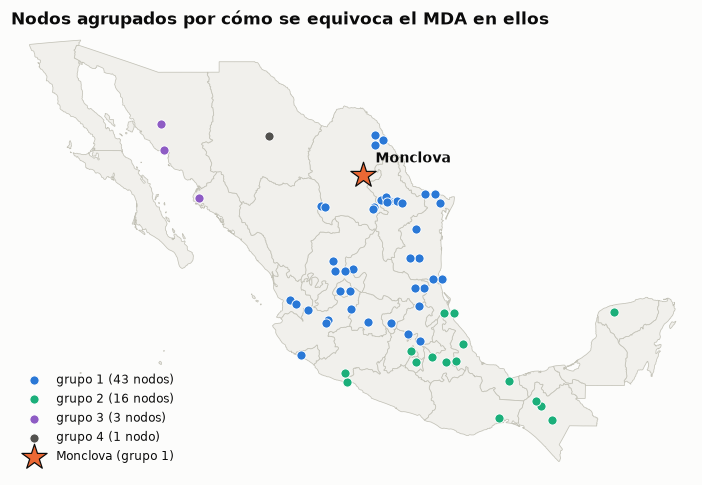

In [8]:
Ym, Xm = red.matrices_nodo('MTR', troncal=True), red.matrices_nodo('MDA', troncal=True)
S = pd.DataFrame({n: (f2.fw(Ym[n], R.c0) - f2.fw(Xm[n], R.c0)).mean(axis=1) for n in Ym}).loc[f2.TRAIN_START:'2024-06-30']
S['monclova'] = (f2.fw(R.c0.Y, R.c0) - f2.fw(R.c0.X, R.c0)).mean(axis=1).loc[S.index]
S = S.dropna(axis=1, thresh=100)                                   # 08RMV-400 no tiene datos en ese periodo
def efectivas(cols):
    """Número efectivo de series: 1 si todas son copias, n si son independientes."""
    l = np.clip(np.linalg.eigvalsh(S[[x for x in cols if x in S]].corr().fillna(0).values), 0, None)
    return l.sum() ** 2 / (l ** 2).sum()
REDES = {'solo Monclova': ['monclova'], 'Monclova + 15 más parecidos': ['monclova'] + PAR15,
         'Monclova + 31 originales': ['monclova'] + list(red.NODOS_RED), 'Monclova + 64': list(S.columns)}
GBS = {'solo Monclova': GB0, 'Monclova + 15 más parecidos': DEC['solo los 15 nodos más parecidos'], 'Monclova + 31 originales': GB31, 'Monclova + 64': GB65}
TE = pd.DataFrame({'series de entrenamiento': {k: len([x for x in v if x in S]) for k, v in REDES.items()},
                   'series efectivamente distintas': {k: efectivas(v) for k, v in REDES.items()},
                   'error del GB en desarrollo': {k: m(P) for k, P in GBS.items()}})
TE['GB vs solo Monclova (%)'] = 100 * (TE['error del GB en desarrollo'] / TE.loc['solo Monclova', 'error del GB en desarrollo'] - 1)
display(TE.round(2)); TE.round(3).to_csv(REP / '06_series_efectivas_dev.csv')

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
x = np.arange(len(TE)); w = 0.38
axs[0].bar(x - w / 2, TE['series de entrenamiento'], w, color=ps.GRIS, label='series de entrenamiento')
axs[0].bar(x + w / 2, TE['series efectivamente distintas'], w, color=ps.AZUL, label='series efectivamente distintas')
for i, (a, b) in enumerate(zip(TE['series de entrenamiento'], TE['series efectivamente distintas'])):
    axs[0].text(i - w / 2, a + 0.8, f'{a:.0f}', ha='center', fontsize=8); axs[0].text(i + w / 2, b + 0.8, f'{b:.1f}', ha='center', fontsize=8)
axs[0].set_xticks(x, [k.replace('Monclova + ', '+ ') for k in TE.index], fontsize=8); axs[0].legend(fontsize=8)
axs[0].set_title('Muchos nodos, pocas series distintas')
axs[1].bar(x, TE['error del GB en desarrollo'], color=[ps.GRIS, ps.GRIS, ps.AZUL, ps.AZUL], width=0.6)
axs[1].axhline(m(X), color=ps.NARANJA, ls='--', lw=1, label=f'MDA ({m(X):.1f})')
for i, v in enumerate(TE['error del GB en desarrollo']): axs[1].text(i, v + 0.6, f'{v:.1f}', ha='center', fontsize=8)
axs[1].set_ylim(TE['error del GB en desarrollo'].min() - 15, TE['error del GB en desarrollo'].max() + 6)
axs[1].set_xticks(x, [k.replace('Monclova + ', '+ ') for k in TE.index], fontsize=8); axs[1].legend(fontsize=8)
axs[1].set_title('Error del GB en desarrollo (MXN/MWh)')
fig.tight_layout(); fig.savefig(FIG / '06_series_efectivas.png'); plt.show()

# ¿Qué nodos son "copias" y cuáles traen algo distinto? Agrupamos los nodos por cómo se parecen sus errores entre sí.
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
Cn = S.corr().fillna(0)
grupo = pd.Series(fcluster(linkage(squareform((1 - Cn.values).clip(0), checks=False), 'average'), 4, 'maxclust'), index=Cn.index)
orden = grupo.groupby(grupo).size().sort_values(ascending=False).index           # el grupo 1 es el más grande
nombres = {g: f'grupo {i + 1}' for i, g in enumerate(orden)}
grupo = grupo.map(nombres)
print('nodos por grupo:', grupo.value_counts().to_dict(), '| Monclova está en el', grupo['monclova'])
print('series efectivas de Monclova junto con cada grupo:', {g: round(efectivas(['monclova'] + [n for n in grupo.index if grupo[n] == g and n != 'monclova']), 2) for g in sorted(set(grupo))},
      '| con todos:', round(efectivas(list(S.columns)), 2))
COLG = dict(zip(sorted(set(grupo)), [ps.AZUL, ps.AQUA, '#8e5cc4', ps.GRIS]))
ub = red.ubicaciones(); ubs = mapas.separar(ub)
fig, ax = plt.subplots(figsize=(9, 5.2))
mapas.fondo(ax)
for g, col in COLG.items():
    d = ubs.loc[[n for n in ubs.index if grupo.get(n) == g and ub.loc[n, 'grupo'] != 'monclova']]
    ax.scatter(d.lon, d.lat, color=col, s=36, ec='white', lw=0.6, zorder=3, label=f'{g} ({len(d)} nodo{"s" if len(d) != 1 else ""})')
mm = ub[ub.grupo == 'monclova']
ax.scatter(mm.lon.mean(), mm.lat.mean(), marker='*', s=300, color=ps.NARANJA, ec='#0b0b0b', lw=0.8, zorder=5, label=f'Monclova ({grupo["monclova"]})')
ax.annotate('Monclova', (mm.lon.mean(), mm.lat.mean()), xytext=(8, 8), textcoords='offset points', fontsize=9, fontweight='bold')
ax.legend(loc='lower left', fontsize=8); ax.set_title('Nodos agrupados por cómo se equivoca el MDA en ellos')
fig.savefig(FIG / '06_mapa_grupos.png', bbox_inches='tight'); plt.show()



Duplicar los nodos no agregó información: con 31 nodos hay 1.5 series realmente distintas y con 64, también 1.5 (se mide con el número efectivo de series, que vale 1 si todas son copias y *n* si son independientes). Usar solo los 15 nodos más parecidos a Monclova da 1.0 series y el GB casi no mejora (233.0, −0.9%). El error del GB sigue ese conteo, no el número de nodos: 235.3 con 1.0, 219.8 y 219.5 con 1.5. Agrupando los nodos por cómo se equivocan, 44 de ellos forman un solo grupo, el de Monclova.

Lo que cuenta es la variedad, no la cantidad ni el parecido: los nodos más parecidos son casi copias de Monclova y enseñan poco.

Con 64 nodos se aprovecha todo lo que hay, y no vale la pena seguir ampliando la red.

## 5. El escalamiento, de un vistazo

,solo Monclova,+ 31 nodos,+ 64 nodos,31 vs solo (%),64 vs solo (%),64 vs 31 (%)
GB,235.3,219.8,219.5,-6.6,-6.7,-0.1
LEAR,219.2,218.3,218.8,-0.4,-0.2,0.2
DNN,221.3,237.3,245.0,7.2,10.7,3.3
NBEATSx,222.9,226.8,229.1,1.8,2.8,1.0
TiDE,219.7,251.0,246.2,14.2,12.0,-1.9
NBEATSx sin MDA,257.6,273.0,269.9,6.0,4.8,-1.1


series efectivas (sección 5): {'solo Monclova': 1.0, 'Monclova + 15 más parecidos': 1.0, 'Monclova + 31 originales': 1.53, 'Monclova + 64': 1.47}


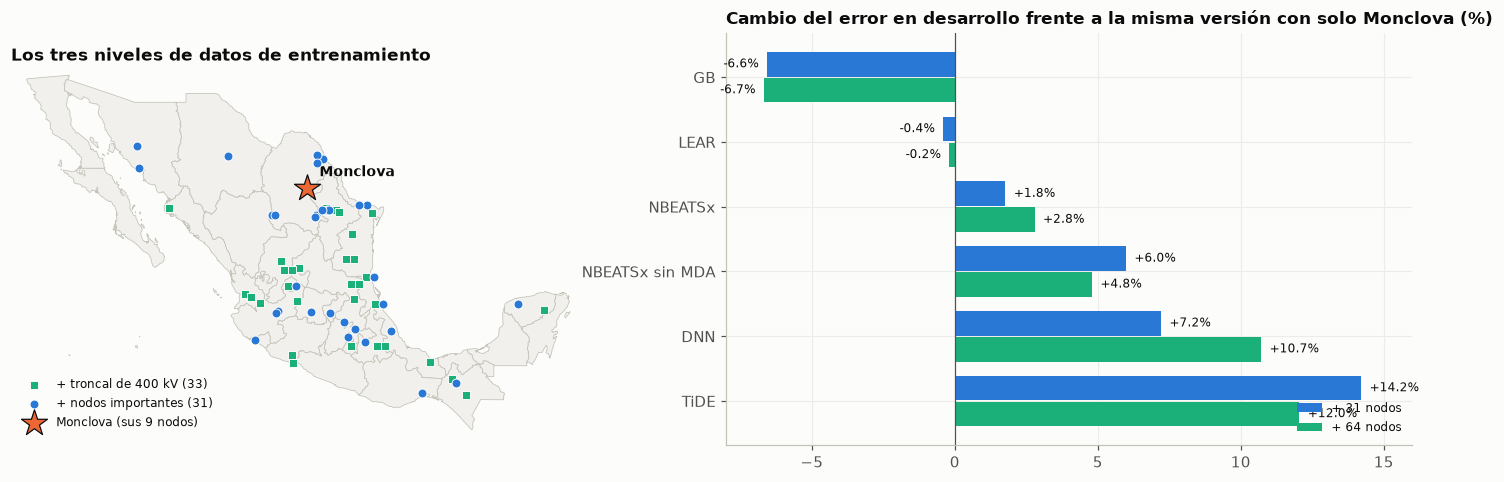

In [9]:
# El escalamiento, modelo por modelo: solo Monclova / + 31 nodos importantes / + la troncal completa (64 nodos).
# Las redes con 31 nodos se entrenan igual que las de 64 (lote de 256, la L1 de siempre) y se leen de caché.
NOMBRE_RED = {'mlp': 'DNN', 'nbeats': 'NBEATSx', 'tide': 'TiDE'}
RED31 = {k: dl.a_precios(cb, dl.correr_dl_red(cb, 'spread', replace(R.hp[a], batch=256), DIAS, troncal=False, nombre=f'{a}_red31'), 'spread') for a, k in NOMBRE_RED.items()}
NB1_31 = dl.a_precios(cb, dl.correr_dl_red(cb, 'sin_mda', replace(R.hp['nbeats'], batch=256), DIAS, troncal=False, nombre='nbeats_sin_mda_red31'), 'sin_mda')
ESC = {'GB': (GB0, GB31, GB65), 'LEAR': (LEAR, LEAR31, LEAR65), **{k: (SOLO[k], RED31[k], RED65[k]) for k in SOLO}, 'NBEATSx sin MDA': (R.P['NBEATSx V1 sin MDA'], NB1_31, NB1_65)}
ESCT = pd.DataFrame({k: {'solo Monclova': m(a), '+ 31 nodos': m(b), '+ 64 nodos': m(c)} for k, (a, b, c) in ESC.items()}).T
ESCT['31 vs solo (%)'] = 100 * (ESCT['+ 31 nodos'] / ESCT['solo Monclova'] - 1); ESCT['64 vs solo (%)'] = 100 * (ESCT['+ 64 nodos'] / ESCT['solo Monclova'] - 1)
ESCT['64 vs 31 (%)'] = 100 * (ESCT['+ 64 nodos'] / ESCT['+ 31 nodos'] - 1)
display(ESCT.round(1)); ESCT.round(2).to_csv(REP / '06_escalamiento_dev.csv')
pickle.dump(ESC, open(ROOT / 'data/processed/exp_cache/nb09_escala.pkl', 'wb'))       # (solo Monclova, 31, 64) de cada modelo, para la escalera (notebook 08)
print('series efectivas (sección 5):', {k: round(v, 2) for k, v in TE['series efectivamente distintas'].items()})

# Figura: a la izquierda, los tres niveles en el mapa; a la derecha, cuánto cambia cada modelo
ub = red.ubicaciones(); ubs = mapas.separar(ub)
fig = plt.figure(figsize=(13, 4.8))
a1 = fig.add_axes([0.0, 0.03, 0.40, 0.9]); a2 = fig.add_axes([0.5, 0.12, 0.48, 0.78])
mapas.fondo(a1)
nuevos = ubs[(ubs.grupo == '400 kV nuevos')]; orig = ubs[(ubs.grupo == '31 originales')]; mm = ub[ub.grupo == 'monclova']
a1.scatter(nuevos.lon, nuevos.lat, color=ps.AQUA, marker='s', s=30, ec='white', lw=0.6, zorder=3, label=f'+ troncal de 400 kV ({len(nuevos)})')
a1.scatter(orig.lon, orig.lat, color=ps.AZUL, s=34, ec='white', lw=0.6, zorder=4, label=f'+ nodos importantes ({len(orig)})')
a1.scatter(mm.lon.mean(), mm.lat.mean(), marker='*', s=320, color=ps.NARANJA, ec='#0b0b0b', lw=0.8, zorder=5, label='Monclova (sus 9 nodos)')
a1.annotate('Monclova', (mm.lon.mean(), mm.lat.mean()), xytext=(8, 8), textcoords='offset points', fontsize=9, fontweight='bold')
a1.legend(loc='lower left', fontsize=8); a1.set_title('Los tres niveles de datos de entrenamiento')
orden = ESCT.sort_values('64 vs solo (%)').index; yy = np.arange(len(orden))
a2.barh(yy - 0.2, ESCT.loc[orden, '31 vs solo (%)'], 0.38, color=ps.AZUL, label='+ 31 nodos'); a2.barh(yy + 0.2, ESCT.loc[orden, '64 vs solo (%)'], 0.38, color=ps.AQUA, label='+ 64 nodos')
for j, k in enumerate(orden):
    for dy, col in ((-0.2, '31 vs solo (%)'), (0.2, '64 vs solo (%)')):
        v = ESCT.loc[k, col]; a2.text(v + (0.3 if v >= 0 else -0.3), j + dy, f'{v:+.1f}%', va='center', ha='left' if v >= 0 else 'right', fontsize=8)
a2.set_yticks(yy, orden); a2.invert_yaxis(); a2.axvline(0, color=ps.GRIS, lw=0.8); a2.legend(fontsize=8, loc='lower right'); a2.set_xlim(-8, 16)
a2.set_title('Cambio del error en desarrollo frente a la misma versión con solo Monclova (%)')
fig.savefig(FIG / '06_escalamiento.png', bbox_inches='tight'); plt.show()

## Decisiones

- **Más nodos ayuda a quien le faltaban ejemplos.** El GB pasa de 229.4 a 222.3 solo por entrenar con 64 nodos (mismas variables), y con 31 nodos el resultado es casi igual que con 64. LEAR mejora poco (−0.2% a −0.4%) y las redes empeoran (DNN +10.7%, TiDE +12.0%, NBEATSx +2.8%, red sin MDA +4.8%).
- **Desde aquí, todos los modelos se entrenan con las filas de Monclova y de los 64 nodos**, aunque a las redes les cueste. Así todos pasan por el mismo camino y la escalera del notebook 08 se puede leer modelo contra modelo; ahí se ve qué tanto les cuesta a las redes y si lo recuperan con más variables.
- Siguiente paso: qué información conviene darles a los modelos, ahora con 64 nodos (notebook 07).